In [1]:
import py_wake

print("PyWake loaded successfully!")

PyWake loaded successfully!


/Users/aronwalter/miniconda3/envs/pywake/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import pandas as pd
import numpy as np
from scipy.stats import weibull_min

# ==========================================
# 1. PARAMETERS
# ==========================================
FILE_NAME = '9 Manston 2008 new.xlsx' 
SHEET_NAME = 'MANSTON'

print(f"Loading data of sheet '{SHEET_NAME}'...")

# ==========================================
# 2. DATA LOADING (Targeting specific sheet)
# ==========================================
# Added sheet_name parameter to target the correct tab
df = pd.read_excel(FILE_NAME, sheet_name=SHEET_NAME, engine='openpyxl', usecols="E:P", header=None)

# Assign temporary column names
df.columns = [
    'Col_E', 'Col_F', 'Col_G', 
    'Col_H', 'Col_I', 'Col_J', # Turbine 1
    'Col_K', 'Col_L', 'Col_M', # Turbine 2
    'Col_N', 'Col_O', 'Col_P'  # Turbine 3
]

# ====================================================================
# CONFIGURATION : Speed choice
# Uncomment the desired speed column for analysis. Options include:
# ====================================================================

# -- Raw 10m data --
# SPEED_COL = 'Col_E'

# -- Turbine 1 --
# SPEED_COL = 'Col_H'  # Turbine 1 - Hub height LOW
# SPEED_COL = 'Col_I'  # Turbine 1 - Hub height MID 
# SPEED_COL = 'Col_J'  # Turbine 1 - Hub height HIGH

# -- Turbine 2 --
#SPEED_COL = 'Col_K'  # Turbine 2 - Hub height LOW
# SPEED_COL = 'Col_L'  # Turbine 2 - Hub height MID
SPEED_COL = 'Col_M'  # Turbine 2 - Hub height HIGH

# -- Turbine 3 --
# SPEED_COL = 'Col_N'  # Turbine 3 - Hub height LOW
# SPEED_COL = 'Col_O'  # Turbine 3 - Hub height MID
# SPEED_COL = 'Col_P'  # Turbine 3 - Hub height HIGH
# ====================================================================
DIR_COL = 'Col_F'


# CORRECTION : comas--> points for decimal conversion
df[SPEED_COL] = df[SPEED_COL].astype(str).str.replace(',', '.')
df[DIR_COL] = df[DIR_COL].astype(str).str.replace(',', '.')

# numeric conversion 
df[SPEED_COL] = pd.to_numeric(df[SPEED_COL], errors='coerce')
df[DIR_COL] = pd.to_numeric(df[DIR_COL], errors='coerce')

# Suppression des lignes où il manque la vitesse ou la direction
df = df.dropna(subset=[SPEED_COL, DIR_COL])
# Convert Knots to m/s
df['Speed_ms'] = df[SPEED_COL] * 0.514444

# Sectors calculation
df['Sector_Index'] = np.round(df[DIR_COL] / 30.0) % 12
total_measurements = len(df)
sector_counts = df['Sector_Index'].value_counts().sort_index()

p_wd = []
A_params = []
k_params = []

print(f"Successfully loaded {total_measurements} valid measurements.")
print("\nCalculating Weibull parameters (A and k) for 12 sectors:")
print("-" * 50)

# ==========================================
# 3. WEIBULL CALCULATION PER SECTOR
# ==========================================
for i in range(12):
    angle = i * 30
    sector_speeds = df[df['Sector_Index'] == i]['Speed_ms'].values
    
    if len(sector_speeds) == 0:
        freq, A, k = 0.0, 0.0, 1.0
    else:
        freq = sector_counts.get(i, 0.0) / total_measurements
        positive_speeds = sector_speeds[sector_speeds > 0.1]
        
        # Safeguard for sectors with no wind variance
        if len(np.unique(positive_speeds)) < 2:
            if len(positive_speeds) > 0:
                A = positive_speeds[0]
                k = 1.0
            else:
                A, k = 0.0, 1.0
        else:
            shape, loc, scale = weibull_min.fit(positive_speeds, floc=0)
            k = shape
            A = scale

    p_wd.append(round(freq, 4))
    A_params.append(round(A, 2))
    k_params.append(round(k, 2))
    
    print(f"Sector {angle:03d}° | Freq (p_wd): {freq:.1%} | A: {A:.2f} m/s | k: {k:.2f}")

# ==========================================
# 4. PYWAKE CODE GENERATION
# ==========================================
print("\n" + "="*50)
print("COPY AND PASTE THIS INTO YOUR PYWAKE SCRIPT:")
print("="*50)
print(f"p_wd = {p_wd}")
print(f"a = {A_params}")
print(f"k = {k_params}")
print(f"my_site = UniformWeibullSite(p_wd={p_wd}, a={A_params}, k={k_params}, ti=0.1)")

Loading data of sheet 'MANSTON'...
Successfully loaded 8395 valid measurements.

Calculating Weibull parameters (A and k) for 12 sectors:
--------------------------------------------------
Sector 000° | Freq (p_wd): 4.7% | A: 8.77 m/s | k: 1.92
Sector 030° | Freq (p_wd): 4.9% | A: 8.24 m/s | k: 2.30
Sector 060° | Freq (p_wd): 5.7% | A: 8.65 m/s | k: 2.64
Sector 090° | Freq (p_wd): 6.5% | A: 8.61 m/s | k: 2.88
Sector 120° | Freq (p_wd): 5.1% | A: 7.24 m/s | k: 2.97
Sector 150° | Freq (p_wd): 5.0% | A: 8.34 m/s | k: 1.91
Sector 180° | Freq (p_wd): 7.6% | A: 9.68 m/s | k: 1.73
Sector 210° | Freq (p_wd): 16.9% | A: 10.65 m/s | k: 2.29
Sector 240° | Freq (p_wd): 21.1% | A: 10.23 m/s | k: 2.55
Sector 270° | Freq (p_wd): 8.2% | A: 8.93 m/s | k: 2.24
Sector 300° | Freq (p_wd): 7.9% | A: 8.28 m/s | k: 2.18
Sector 330° | Freq (p_wd): 6.3% | A: 9.45 m/s | k: 2.23

COPY AND PASTE THIS INTO YOUR PYWAKE SCRIPT:
p_wd = [np.float64(0.0471), np.float64(0.0492), np.float64(0.0572), np.float64(0.0653), n

In [32]:
# Define the WindTurbine object
import os
import numpy as np
import matplotlib.pyplot as plt
from py_wake.utils.plotting import setup_plot

In [6]:
# Creating custom turbine for Vestas V136-4.5
import numpy as np
from py_wake.wind_turbines.power_ct_functions import PowerCtTabular
from py_wake.wind_turbines import WindTurbine, WindTurbines

# Wind speed (m/s)[cite: 1]
u_1 = np.array([
    0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 
    5.0, 5.5, 6.0, 6.5, 7.0, 7.5, 8.0, 8.5, 9.0, 9.5, 
    10.0, 10.5, 11.0, 11.5, 12.0, 12.5, 13.0, 13.5, 14.0, 14.5, 
    15.0, 15.5, 16.0, 16.5, 17.0, 17.5, 18.0, 18.5, 19.0, 19.5, 
    20.0, 20.5, 21.0, 21.5, 22.0, 22.5, 23.0, 23.5, 24.0, 24.5, 
    25.0, 25.5, 26.0, 26.5, 27.0, 27.5, 28.0, 28.5, 29.0, 29.5, 30.0
])

# Thrust coefficient (ct)[cite: 1]
ct_1 = np.array([
    0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.873, 0.847, 0.845, 0.843, 
    0.844, 0.840, 0.834, 0.828, 0.821, 0.814, 0.816, 0.799, 0.746, 0.675, 
    0.608, 0.552, 0.499, 0.448, 0.396, 0.346, 0.303, 0.269, 0.239, 0.213, 
    0.191, 0.172, 0.156, 0.142, 0.130, 0.119, 0.110, 0.102, 0.094, 0.087, 
    0.081, 0.075, 0.071, 0.067, 0.063, 0.059, 0.055, 0.051, 0.048, 0.044, 
    0.041, 0.039, 0.036, 0.033, 0.031, 0.029, 0.026, 0.024, 0.021, 0.019, 0.017
])

# Power (kW)[cite: 1] (Multiply by 1000 if your model requires Watts)
power_1 = np.array([
    0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 55.0, 130.0, 220.0, 331.0, 
    471.0, 639.0, 841.0, 1081.0, 1362.0, 1681.0, 2042.0, 2441.0, 2845.0, 3214.0, 
    3552.0, 3867.0, 4128.0, 4328.0, 4442.0, 4486.0, 4498.0, 4498.0, 4500.0, 4500.0, 
    4500.0, 4500.0, 4500.0, 4500.0, 4500.0, 4500.0, 4500.0, 4500.0, 4500.0, 4500.0, 
    4500.0, 4500.0, 4500.0, 4498.0, 4473.0, 4421.0, 4336.0, 4230.0, 4131.0, 4044.0, 
    3952.0, 3858.0, 3756.0, 3620.0, 3456.0, 3261.0, 3033.0, 2789.0, 2548.0, 2548.0, 2548.0
])

# 2. Define your target hub heights
hub_heights = [82,112]

# 3. Create them dynamically and inject them directly into your workspace variables
turbines = {}
for hh in hub_heights:
    name = f"v136_45_{hh}"
    
    # Create the turbine object
    turbine_obj = WindTurbine(
        name=name,
        diameter=136,
        hub_height=hh,
        powerCtFunction=PowerCtTabular(u_1, power_1, 'kW', ct_1)
    )
    
    # Store in a dictionary for easy iteration
    turbines[name] = turbine_obj
    
    # OPTIONAL: This dynamically creates variables named `v126_345_117`, `v126_345_137`, etc., 
    # so you can type them directly into your cells later!
    locals()[name] = turbine_obj

In [4]:
# Creating custom turbine for Nordex_N149_5
# Wind speed (m/s)[cite: 2]
u_2 = np.array([
    0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 
    5.0, 5.5, 6.0, 6.5, 7.0, 7.5, 8.0, 8.5, 9.0, 9.5, 
    10.0, 10.5, 11.0, 11.5, 12.0, 12.5, 13.0, 13.5, 14.0, 14.5, 
    15.0, 15.5, 16.0, 16.5, 17.0, 17.5, 18.0, 18.5, 19.0, 19.5, 
    20.0, 20.5, 21.0, 21.5, 22.0, 22.5, 23.0, 23.5, 24.0, 24.5, 
    25.0, 25.5, 26.0, 26.5, 27.0, 27.5, 28.0, 28.5, 29.0, 29.5, 30.0
])

# Thrust coefficient (ct)[cite: 2]
ct_2 = np.array([
    0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.835, 0.825, 0.815, 0.806, 
    0.798, 0.793, 0.790, 0.788, 0.788, 0.784, 0.767, 0.742, 0.710, 0.671, 
    0.627, 0.579, 0.531, 0.484, 0.437, 0.392, 0.352, 0.316, 0.284, 0.255, 
    0.229, 0.206, 0.186, 0.169, 0.154, 0.141, 0.130, 0.120, 0.112, 0.104, 
    0.098, 0.093, 0.088, 0.084, 0.081, 0.075, 0.069, 0.064, 0.059, 0.055, 
    0.051, 0.047, 0.044, 0.0,  0.0,  0.0,  0.0,  0.0,  0.0,  0.0,  0.0
])

# Power (kW)[cite: 2] (Multiply by 1000 if your PyWake setup requires Watts)
power_2 = np.array([
    0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 29.0, 113.0, 233.0, 383.0, 
    561.0, 773.0, 1023.0, 1317.0, 1658.0, 2050.0, 2497.0, 2988.0, 3496.0, 4001.0, 
    4477.0, 4851.0, 5122.0, 5309.0, 5427.0, 5487.0, 5500.0, 5500.0, 5500.0, 5500.0, 
    5500.0, 5500.0, 5500.0, 5500.0, 5500.0, 5500.0, 5500.0, 5500.0, 5500.0, 5500.0, 
    5500.0, 5500.0, 5500.0, 5500.0, 5469.0, 5387.0, 5278.0, 5147.0, 5039.0, 4891.0, 
    4782.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0
])

# 2. Define your target hub heights
hub_heights_2 = [105, 135, 164]

# 3. Create them dynamically and inject them directly into your workspace variables
turbines_2 = {}
for hh in hub_heights_2:
    name = f"Nordex_N149_5_{hh}"
    
    # Create the turbine object
    turbine_obj = WindTurbine(
        name=name,
        diameter=149,
        hub_height=hh,
        powerCtFunction=PowerCtTabular(u_2, power_2, 'kW', ct_2)
    )
    
    # Store in a dictionary for easy iteration
    turbines_2[name] = turbine_obj
    
    # OPTIONAL: This dynamically creates variables named `v126_345_117`, `v126_345_137`, etc., 
    # so you can type them directly into your cells later!
    locals()[name] = turbine_obj

In [5]:
# Creating custom turbine for v162_6
# Wind speed (m/s)[cite: 2]
u_3 = np.array([
    0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 
    5.0, 5.5, 6.0, 6.5, 7.0, 7.5, 8.0, 8.5, 9.0, 9.5, 
    10.0, 10.5, 11.0, 11.5, 12.0, 12.5, 13.0, 13.5, 14.0, 14.5, 
    15.0, 15.5, 16.0, 16.5, 17.0, 17.5, 18.0, 18.5, 19.0, 19.5, 
    20.0, 20.5, 21.0, 21.5, 22.0, 22.5, 23.0, 23.5, 24.0, 24.5, 
    25.0, 25.5, 26.0, 26.5, 27.0, 27.5, 28.0, 28.5, 29.0, 29.5, 30.0
])

# Thrust coefficient (ct)[cite: 2]
ct_3 = np.array([
    0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.908, 0.882, 0.853, 0.837, 
    0.820, 0.814, 0.812, 0.810, 0.807, 0.804, 0.800, 0.793, 0.763, 0.701, 
    0.635, 0.559, 0.484, 0.413, 0.356, 0.310, 0.273, 0.242, 0.216, 0.193, 
    0.174, 0.158, 0.144, 0.131, 0.120, 0.111, 0.100, 0.089, 0.079, 0.070, 
    0.062, 0.055, 0.048, 0.043, 0.038, 0.033, 0.029, 0.025, 0.022, 0.0, 
    0.0,  0.0,  0.0,  0.0,  0.0,  0.0,  0.0,  0.0,  0.0,  0.0,  0.0
])

# Power (kW)[cite: 2] (Multiply by 1000 if your PyWake setup requires Watts)
power_3 = np.array([
    0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 32.0, 150.0, 292.0, 467.0, 
    676.0, 927.0, 1229.0, 1584.0, 2000.0, 2476.0, 3017.0, 3624.0, 4264.0, 4859.0, 
    5380.0, 5734.0, 5932.0, 5983.0, 5998.0, 6000.0, 6000.0, 6000.0, 6000.0, 6000.0, 
    6000.0, 6000.0, 6000.0, 6000.0, 6000.0, 6000.0, 6000.0, 6000.0, 5846.0, 5581.0, 
    5360.0, 5128.0, 4844.0, 4555.0, 4268.0, 3985.0, 3690.0, 3383.0, 3102.0, 2801.0, 
    2479.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0
])

# 2. Define your target hub heights
hub_heights_3 = [119, 149, 166]

# 3. Create them dynamically and inject them directly into your workspace variables
turbines_3 = {}
for hh in hub_heights_3:
    name = f"v162_6_{hh}"
    
    # Create the turbine object
    turbine_obj = WindTurbine(
        name=name,
        diameter=162,
        hub_height=hh,
        powerCtFunction=PowerCtTabular(u_3, power_3, 'kW', ct_3)
    )
    
    # Store in a dictionary for easy iteration
    turbines_3[name] = turbine_obj
    
    # OPTIONAL: This dynamically creates variables named `v126_345_117`, `v126_345_137`, etc., 
    # so you can type them directly into your cells later!
    locals()[name] = turbine_obj

Name:		v136_45_82	v136_45_112	v162_6_119	v162_6_149	v162_6_166	Nordex_N149_5_105	Nordex_N149_5_135	Nordex_N149_5_164
Diameter[m]	136.0	136.0	162.0	162.0	162.0	149.0	149.0	149.0
Hubheigt[m]	82.0	112.0	119.0	149.0	166.0	105.0	135.0	164.0


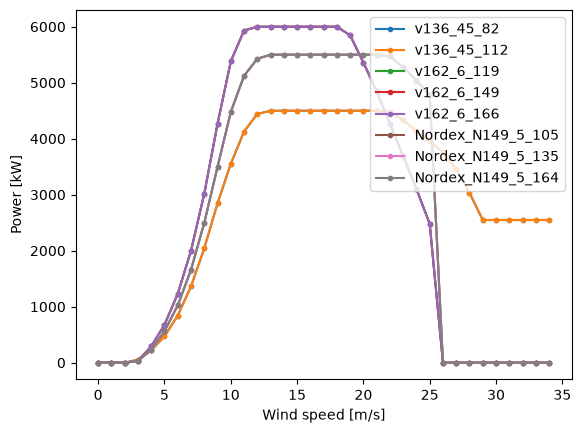

In [10]:
# Collect all wind turbine models into a single object
import matplotlib.pyplot as plt

wts = WindTurbines.from_WindTurbine_lst([v136_45_82, v136_45_112, v162_6_119, v162_6_149, v162_6_166, Nordex_N149_5_105, Nordex_N149_5_135, Nordex_N149_5_164])

# Print information
types = wts.types()
print ("Name:\t\t%s" % "\t".join(wts.name(types)))
print('Diameter[m]\t%s' % "\t".join(map(str,wts.diameter(type=types))))
print('Hubheigt[m]\t%s' % "\t".join(map(str,wts.hub_height(type=types))))

# Print out the power curves of all turbines
ws = np.arange(0,35)
plt.xlabel('Wind speed [m/s]')
plt.ylabel('Power [kW]')

for t in types:
    plt.plot(ws, wts.power(ws, type=t)*1e-3,'.-', label=wts.name(t))
plt.legend(loc=1)

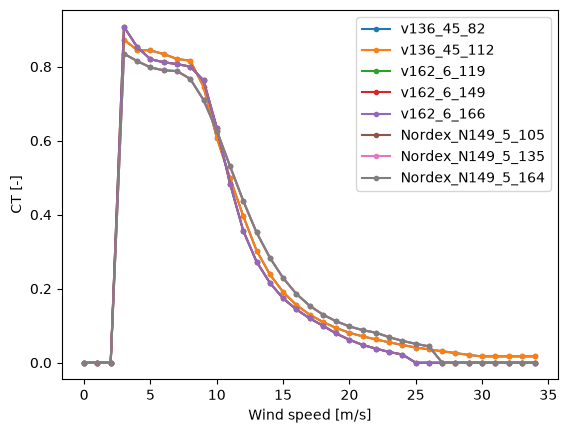

In [11]:
# Print out CT - curves
plt.xlabel('Wind speed [m/s]')
plt.ylabel('CT [-]')

for t in types:
    plt.plot(ws, wts.ct(ws, type=t),'.-', label=wts.name(t))
plt.legend(loc=1)

In [12]:
import os
from IPython.display import HTML
from matplotlib.animation import FuncAnimation, PillowWriter
from numpy import newaxis as na
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt
import numpy as np
from py_wake import NOJ, NOJLocal
from py_wake.examples.data.ParqueFicticio import ParqueFicticioSite, ParqueFicticio_path
from py_wake.examples.data.dtu10mw._dtu10mw import DTU10MW
from py_wake.examples.data.hornsrev1 import Hornsrev1Site, Hornsrev1WRFSite, V80
from py_wake.examples.data.iea37 import IEA37Site
from py_wake.flow_map import XYGrid
from py_wake.site import UniformSite, UniformWeibullSite, WaspGridSite, XRSite
from py_wake.site.distance import StraightDistance
from py_wake.site.shear import PowerShear
from py_wake.utils import layouts
from py_wake.utils import weibull
from py_wake.utils.maps import dk_coast
from py_wake.utils.plotting import setup_plot
from py_wake.utils.functions import mean_deg
import xarray as xr
xr.set_options(display_expand_data=True);

#specifying the necessary parameters for the UniformWeibullSite object
site_test = UniformWeibullSite(p_wd = [np.float64(0.0471), np.float64(0.0492), np.float64(0.0572), np.float64(0.0653), np.float64(0.0505), np.float64(0.0504), np.float64(0.0756), np.float64(0.1693), np.float64(0.2107), np.float64(0.0822), np.float64(0.0792), np.float64(0.0634)], # Need to input sector frequencies
                          a = [np.float64(5.88), np.float64(5.53), np.float64(5.8), np.float64(5.77), np.float64(4.86), np.float64(5.59), np.float64(6.49), np.float64(7.14), np.float64(6.86), np.float64(5.99), np.float64(5.55), np.float64(6.34)],  # Weibull scale parameter
                          k = [np.float64(1.92), np.float64(2.3), np.float64(2.64), np.float64(2.88), np.float64(2.97), np.float64(1.91), np.float64(1.73), np.float64(2.29), np.float64(2.55), np.float64(2.24), np.float64(2.18), np.float64(2.23)],  # Weibull shape parameter
                          ti = 0.1)

# As site is flat, the default StraightDistance function is used to calculate wake effects (terrain mapping effects only relevant for more mountainous terrain)

In [13]:
# import and setup site and windTurbines
from tqdm.notebook import tqdm
from py_wake.utils import layouts
from py_wake.utils.profiling import timeit, profileit
from py_wake.utils.plotting import setup_plot
from py_wake.wind_farm_models import All2AllIterative
from py_wake.deficit_models import BastankhahGaussianDeficit
from py_wake.superposition_models import LinearSum
from py_wake.superposition_models import SquaredSum

xr.set_options(display_expand_data=False)

site = site_test

# 1. Define your initial turbine x and y coordinates here once
initial_x = np.array([200, 500, 800, 1100])
initial_y = np.array([300, 300, 600, 600])

# 2. Attach initial_position directly to site_test as an (N, 2) array
# TopFarm / PyWake expects it shaped as [[x1, y1], [x2, y2], ...]
site_test.initial_position = np.column_stack((initial_x, initial_y))

windTurbines = v126_345_117

wf_model = All2AllIterative(
    site=site_test,
    windTurbines=v126_345_117,
    wake_deficitModel=BastankhahGaussianDeficit(),
    superpositionModel=SquaredSum()
)

#this allows you to see what type of engineering models you are simulating
print(wf_model)

# 5. Run your simulation
# Run your simulation
sim_res = wf_model(initial_x, initial_y)

# Use lowercase .aep() instead of .AEP()
print(f"Total AEP: {sim_res.aep().sum():.3f} GWh")

NameError: name 'v126_345_117' is not defined

In [16]:
# This converts the coordinates of out eligible area into x-y coordinates
# Assumes that the origin is at the bottom left of the shape
import numpy as np
from pyproj import Proj

# Paste your extracted coordinate string here directly from the KML
coords_text = """
1.206860519027202,51.36446385128804,0 1.228540535625071,51.36084646145472,0 1.231326914666149,51.36188554554997,0 1.230900428385338,51.36335221424344,0 1.231327805526934,51.36484423631089,0 1.232271635958224,51.36622022749638,0 1.234157153928741,51.36720473911184,0 1.235699875038621,51.36754714218748,0 1.237311169556172,51.36773970677682,0 1.23816843336801,51.36904525549213,0 1.23998567737952,51.37011530661318,0 1.242180078810307,51.37080004683563,0 1.244278951540922,51.37099084556765,0 1.257965756297754,51.37142367570682,0 1.256980499819131,51.37685128614747,0 1.25101941585005,51.37685381922977,0 1.224173520164562,51.3787160209091,0 1.224263858984787,51.37828483960372,0 1.225127525628988,51.37738319886369,0 1.225643005910668,51.3759615509838,0 1.225426984561819,51.37490328765479,0 1.225044701109166,51.37401101384313,0 1.22547755707124,51.37160360959665,0 1.20754064599127,51.36984418480619,0 1.205743544487601,51.36788013238516,0 1.206860519027202,51.36446385128804,0 
"""

# 1. Parse longitude and latitude values
raw_coords = [list(map(float, c.split(',')[:2])) for c in coords_text.strip().split()]
lons = np.array([c[0] for c in raw_coords])
lats = np.array([c[1] for c in raw_coords])

# 2. Convert Lat/Lon to UTM meters (Zone 31N covers Kent, UK)
proj = Proj(proj='utm', zone=31, ellps='WGS84', datum='WGS84')
x_utm, y_utm = proj(lons, lats)

# 3. Shift coordinates so the bottom-left corner (min x, min y) is (0, 0)
x_origin = x_utm.min()
y_origin = y_utm.min()

site_boundary_vertices = np.column_stack((x_utm - x_origin, y_utm - y_origin))

print("Generated Site Boundary Vertices (meters):\n", site_boundary_vertices)


Generated Site Boundary Vertices (meters):
 [[  68.45770514  438.93300351]
 [1567.90857637    0.        ]
 [1764.67378761  110.86284197]
 [1738.91865294  274.67123971]
 [1772.67145429  439.86507053]
 [1842.0607912   591.2897853 ]
 [1975.94537651  697.60419361]
 [2084.24575496  733.09415252]
 [2196.91712117  751.80971222]
 [2260.07640035  895.55163103]
 [2389.42056276 1011.50279578]
 [2543.98221539 1083.9814217 ]
 [2690.57524461 1101.69788268]
 [3644.33970267 1127.10586596]
 [3590.11366662 1732.28380318]
 [3175.27340448 1742.44520137]
 [1312.0189506  1994.43238928]
 [1317.14421963 1946.33306988]
 [1374.81957794 1844.61585406]
 [1406.86657292 1685.6613361 ]
 [1388.98447867 1568.3471465 ]
 [1359.9772697  1469.77104965]
 [1383.62333263 1201.34044602]
 [ 130.42779462 1036.0622954 ]
 [   0.          820.72138312]
 [  68.45770514  438.93300351]]


Text(0.5, 1.0, 'Wake map for 270 deg and 9 m/s')

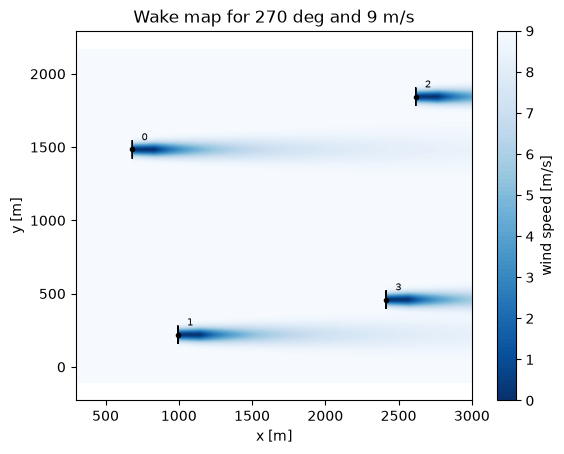

In [46]:
#change the wind speed and wind direction to visualize different flow cases
sim_res_optimised = wf_model(state['x'], state['y'])

wsp = 9
wdir = 270
flow_map = sim_res_optimised.flow_map(grid=None, # defaults to HorizontalGrid(resolution=500, extend=0.2), see below
                            wd=wdir,
                            ws=wsp)

plt.figure()
flow_map.plot_wake_map()
plt.xlabel('x [m]')
plt.ylabel('y [m]')
plt.title('Wake map for'+ f' {wdir} deg and {wsp} m/s')

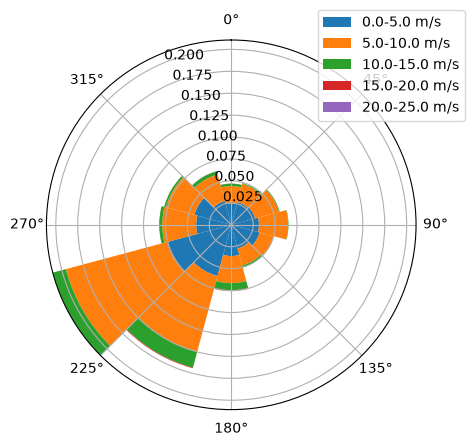

In [47]:
# Plots power against wind speed for every 30th degree of wind direction (should target each sector if we do 12 sectors)
# Assumes turbines "yaw" - turbine moves to face the direction of incoming wind  at all times
for P_ws in sim_res.P[::30]:
    P_ws.plot(label=f'WD={P_ws.wd.item()}')
setup_plot()

# Plots a wind rose
# 12 is no. of wind directions and the ws = wind speed bins
_ = site.plot_wd_distribution(n_wd=12, ws_bins=[0,5,10,15,20,25])

In [20]:
from matplotlib.path import Path

def initial_layout(n_wt, vertices, min_spacing, seed=0, max_tries=50000):
    """Random points inside the boundary, all at least min_spacing apart."""
    rng = np.random.default_rng(seed)
    vertices = np.asarray(vertices, dtype=float)
    poly = Path(vertices)
    lo, hi = vertices.min(axis=0), vertices.max(axis=0)
    pts = []
    for _ in range(max_tries):
        p = rng.uniform(lo, hi)
        if not poly.contains_point(p):
            continue
        if pts and np.hypot(*(np.array(pts) - p).T).min() < min_spacing:
            continue
        pts.append(p)
        if len(pts) == n_wt:
            return np.array(pts).T          # returns x, y
    raise RuntimeError(f"Could not place {n_wt} turbines with {min_spacing:.0f} m spacing "
                       f"inside the boundary. Reduce spacing or turbine count.")

In [21]:
def get_topfarmProblem(wfm, x0, y0, grad_method, maxiter, n_cpu, vertices):
    return TopFarmProblem(
        design_vars={'x': x0, 'y': y0},
        cost_comp=PyWakeAEPCostModelComponent(
            windFarmModel=wfm, n_wt=len(x0),
            grad_method=grad_method, n_cpu=n_cpu,
            wd=wfm.site.default_wd, ws=wfm.site.default_ws),
        driver=EasyScipyOptimizeDriver(maxiter=maxiter),
        constraints=[XYBoundaryConstraint(vertices),
                     SpacingConstraint(min_spacing=2 * wfm.windTurbines.diameter())])

In [23]:
import pandas as pd
from tqdm.auto import tqdm

def sweep_turbine_numbers(wfm, vertices, n_list, maxiter=100, n_starts=1,
                          grad_method=fd, n_cpu=1):
    D = wfm.windTurbines.diameter()
    rows, layouts = [], {}
    for n_wt in tqdm(n_list):
        best = None
        for s in range(n_starts):                      # optional multi-start
            x0, y0 = initial_layout(n_wt, vertices, min_spacing=2.5 * D, seed=s)
            tf = get_topfarmProblem(wfm, x0, y0, grad_method, maxiter, n_cpu, vertices)
            _, state, _ = tf.optimize(disp=False)
            x, y = state['x'], state['y']
            aep = wfm(x, y).aep().sum().item()         # recompute rather than trust -cost
            if best is None or aep > best[0]:
                best = (aep, x, y, wfm(x0, y0).aep().sum().item())
        aep, x, y, aep_init = best
        aep_nowake = wfm(x, y).aep(with_wake_loss=False).sum().item()
        rows.append({'n_wt': n_wt, 'aep_initial_GWh': aep_init, 'aep_opt_GWh': aep,
                     'aep_per_turbine_GWh': aep / n_wt,
                     'wake_loss_%': 100 * (1 - aep / aep_nowake)})
        layouts[n_wt] = (x, y)
    return pd.DataFrame(rows), layouts

results, layouts = sweep_turbine_numbers(wf_model, site_boundary_vertices,
                                         n_list=range(5, 16, 4), maxiter=20)
print(results)

  0%|          | 0/3 [00:00<?, ?it/s]

INFO: checking out_of_order...
INFO:     out_of_order check complete (0.000169 sec).
INFO: checking system...
INFO:     system check complete (0.000006 sec).
INFO: checking solvers...
INFO:     solvers check complete (0.000071 sec).
INFO: checking dup_inputs...
INFO:     dup_inputs check complete (0.000018 sec).
INFO: checking missing_recorders...
INFO:     missing_recorders check complete (0.000001 sec).
INFO: checking unserializable_options...
INFO:     unserializable_options check complete (0.000128 sec).
INFO: checking comp_has_no_outputs...
INFO:     comp_has_no_outputs check complete (0.000036 sec).
INFO: checking auto_ivc_warnings...
INFO:     auto_ivc_warnings check complete (0.000003 sec).
INFO: checking out_of_order...
INFO:     out_of_order check complete (0.000059 sec).
INFO: checking system...
INFO:     system check complete (0.000005 sec).
INFO: checking solvers...
INFO:     solvers check complete (0.000045 sec).
INFO: checking dup_inputs...
INFO:     dup_inputs check com

 33%|███▎      | 1/3 [00:02<00:04,  2.19s/it]

Iteration limit reached    (Exit mode 9)
            Current function value: -36.77724719999115
            Iterations: 20
            Function evaluations: 21
            Gradient evaluations: 21
Optimization FAILED.
Iteration limit reached
-----------------------------------
INFO: checking out_of_order...
INFO:     out_of_order check complete (0.000081 sec).
INFO: checking system...
INFO:     system check complete (0.000007 sec).
INFO: checking solvers...
INFO:     solvers check complete (0.000038 sec).
INFO: checking dup_inputs...
INFO:     dup_inputs check complete (0.000015 sec).
INFO: checking missing_recorders...
INFO:     missing_recorders check complete (0.000001 sec).
INFO: checking unserializable_options...
INFO:     unserializable_options check complete (0.000065 sec).
INFO: checking comp_has_no_outputs...
INFO:     comp_has_no_outputs check complete (0.000013 sec).
INFO: checking auto_ivc_warnings...
INFO:     auto_ivc_warnings check complete (0.000001 sec).
INFO: checking

 67%|██████▋   | 2/3 [00:10<00:05,  5.80s/it]

Iteration limit reached    (Exit mode 9)
            Current function value: -62.47316184660055
            Iterations: 20
            Function evaluations: 21
            Gradient evaluations: 21
Optimization FAILED.
Iteration limit reached
-----------------------------------
INFO: checking out_of_order...
INFO:     out_of_order check complete (0.000093 sec).
INFO: checking system...
INFO:     system check complete (0.000005 sec).
INFO: checking solvers...
INFO:     solvers check complete (0.000046 sec).
INFO: checking dup_inputs...
INFO:     dup_inputs check complete (0.000017 sec).
INFO: checking missing_recorders...
INFO:     missing_recorders check complete (0.000001 sec).
INFO: checking unserializable_options...
INFO:     unserializable_options check complete (0.000062 sec).
INFO: checking comp_has_no_outputs...
INFO:     comp_has_no_outputs check complete (0.000013 sec).
INFO: checking auto_ivc_warnings...
INFO:     auto_ivc_warnings check complete (0.000001 sec).
INFO: checking

100%|██████████| 3/3 [00:31<00:00, 10.41s/it]

Iteration limit reached    (Exit mode 9)
            Current function value: -85.62270216700813
            Iterations: 20
            Function evaluations: 21
            Gradient evaluations: 21
Optimization FAILED.
Iteration limit reached
-----------------------------------
   n_wt  aep_initial_GWh  aep_opt_GWh  aep_per_turbine_GWh  wake_loss_%
0     5        35.722997    36.777247             7.355449     3.206948
1     9        60.731225    62.473162             6.941462     8.654755
2    13        81.683549    85.622702             6.586362    13.327655


NameError: name 'results' is not defined

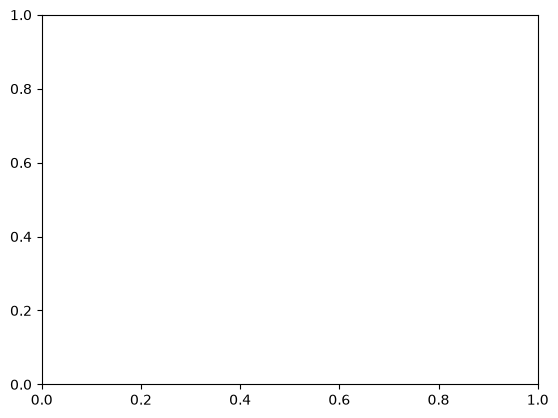

In [ ]:
fig, ax = plt.subplots()
ax.plot(results['n_wt'], results['aep_opt_GWh'], 'o-')
ax.set_xlabel('Number of turbines'); ax.set_ylabel('Optimised AEP [GWh]')
ax2 = ax.twinx()
ax2.plot(results['n_wt'], results['aep_per_turbine_GWh'], 's--', color='C1')
ax2.set_ylabel('AEP per turbine [GWh]', color='C1')